# Case Study 27 (Capstone) — What Drives Loan Default, and What Should Risk Do?

**The full workflow in one case: business problem → target definition → data quality → exploratory analysis → pre-stated hypotheses and tests →
confounding and multicollinearity → logistic regression → diagnostics → classification and calibration metrics → out-of-time validation →
cost-based decision → recommendation**

| | |
|---|---|
| **Domain** | Credit risk: unsecured personal loans |
| **Stakeholders** | Chief Risk Officer, Head of Retail Lending, Credit Policy |
| **Difficulty** | Advanced |
| **Importance** | 🔴 MUST GO THROUGH |
| **Builds on** | Cases 01 to 26: especially 02 (tests), 08 and 21 (confounding), 09 (multicollinearity), 11 and 12 (logistic regression, metrics), 13 (model validation), 17 (missing data), 19 (multiple testing) |
| **Data** | About 24,000 loan applications from 2022 (development) and 2023 (out-of-time test), with a 12-month default flag |

> **This dataset is synthetic** and was generated to reproduce a realistic business scenario. It is not actual customer data.
> See `src/generate_data.py`. Answer keys (true coefficients, true default probability of every loan) exist only because the data are simulated;
> the notebook opens them **only in Section 14**.

**What you will learn**

1. How to run a complete, defensible analysis on a messy, multi-variable problem and know what to do at each step.
2. How to separate **real drivers** from **proxies** (the interest rate), **confounded** variables (the agent channel) and **noise**.
3. How to report a model in odds, probabilities and policy terms, validate it out of time, and say what it cannot tell us.

## Section 1 — Business context

The Chief Risk Officer writes:

> *"Default on our personal loans was 7.5% last year, above the 6% we priced for. The monthly dashboard says three things: loans sold by agents default almost twice as often as online loans; borrowers on higher interest rates default more; and
> higher-income borrowers default less. I want to (1) stop agent-sourced lending, (2) raise the minimum income, and (3) price harder on high-rate segments. Before I sign, tell me what actually drives default, how well we can predict it,
> and what policy we should adopt."*

## Section 2 — Business questions

1. What is the data quality, and can we trust it?
2. Which borrower and loan characteristics are associated with default? Which of the dashboard's three claims survive adjustment?
3. Which variables are real drivers, which are proxies, and which are noise?
4. How well can default be predicted, and does the model hold out of time?
5. What approval policy maximises expected profit, and what should Risk do?

## Section 3 — Statistical translation

| # | Business question | Statistical question | Method |
|---|---|---|---|
| 1 | Data quality | Duplicates, label problems, missingness, outliers, impossible values | Profiling, missingness analysis (MCAR/MAR) |
| 2 | Associations | Univariate relationships with default, with multiplicity control | Mann-Whitney / AUC, chi-square, Benjamini-Hochberg |
| 3 | Real vs apparent drivers | Does an effect survive adjustment? Are predictors redundant? | Raw vs adjusted odds ratios, correlation, VIF, likelihood-ratio tests |
| 4 | Prediction | Discrimination, calibration, stability out of time | Logistic regression, AUC, PR-AUC, KS, calibration slope, PSI |
| 5 | Policy | Cost-based cut-off | Expected profit at probability thresholds |

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multitest import multipletests
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "00_shared_resources").is_dir())
sys.path.insert(0, str(ROOT / "00_shared_resources"))
from utils import case_paths, save_table, fmt_p, rng_for_case
from plotting import set_style, save_fig, add_note, COLORS, CATEGORICAL, PRIMARY, HIGHLIGHT, INK, INK_MUTED

CASE_DIR = ROOT / "case_studies" / "27_capstone_loan_default_drivers"
PATHS = case_paths(CASE_DIR)
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
warnings.filterwarnings("ignore")
rng = rng_for_case(2727)
pctfmt = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

## Section 4 — Define the target and load the data

**Target:** `defaulted_12m` = 1 if the loan was 90+ days past due at any time within 12 months of disbursement. Applications from **2022** are the development sample; **2023** is an out-of-time test sample, never used for fitting or selection.
(Only loans with a full 12 months of history are included, so the target is observed for everyone.)

In [2]:
raw = pd.read_csv(PATHS["data"] / "loan_applications.csv")
print(f"{len(raw):,} rows x {raw.shape[1]} columns")
display(raw.head())
print(raw.dtypes.to_string())

24,060 rows x 16 columns


,loan_id,application_date,age,monthly_income,employment_type,years_in_job,credit_score,dti_pct,loan_amount,term_months,interest_rate,channel,city_tier,prior_delinquency,utilisation_pct,defaulted_12m
0,LN27100000,2022-10-10,42.0000,"37,800.0000",gig,8.7000,584.0000,12.9000,"61,000.0000",36,12.1400,branch,1,0,39.4000,0
1,LN27100001,2022-08-05,42.0000,"40,200.0000",Gig,8.3000,664.0000,20.2000,"322,000.0000",24,9.9700,agent,2,0,49.9000,0
2,LN27100002,2022-02-13,36.0000,"58,900.0000",Salaried,10.7000,548.0000,16.5000,"122,000.0000",36,12.2600,online,1,1,42.0000,0
3,LN27100003,2022-05-23,25.0000,"25,400.0000",Salaried,2.2000,603.0000,28.4000,"419,000.0000",36,11.9100,online,1,0,38.7000,0
4,LN27100004,2022-10-15,30.0000,"26,400.0000",salaried,2.7000,698.0000,21.1000,"326,000.0000",48,9.4000,online,2,0,48.1000,0


loan_id               object
application_date      object
age                  float64
monthly_income       float64
employment_type       object
years_in_job         float64
credit_score         float64
dti_pct              float64
loan_amount          float64
term_months            int64
interest_rate        float64
channel               object
city_tier              int64
prior_delinquency     object
utilisation_pct      float64
defaulted_12m          int64


## Section 5 — Data quality

In [3]:
log = []
n0 = len(raw)
dups = raw.duplicated(keep="first").sum(); log.append(("exact duplicate rows", int(dups), "removed"))
df = raw.drop_duplicates().reset_index(drop=True)
print(f"Duplicate loan_ids after removing exact duplicates: {df.loan_id.duplicated().sum()}")
print("Employment labels before cleaning:", sorted(df.employment_type.unique()))
df["employment_type"] = df["employment_type"].str.strip().str.lower().str.replace("-", "_")
print("after:", sorted(df.employment_type.unique()))
log.append(("employment labels with inconsistent case or spaces", int((~raw.drop_duplicates().employment_type.isin(["Salaried", "Self-employed", "Gig"])).sum()), "standardised to salaried / self_employed / gig"))
bad_age = df[(df.age < 18) | (df.age > 80)]
print("Impossible ages:", bad_age[["loan_id", "age"]].values.tolist())
log.append(("impossible ages (<18 or >80)", len(bad_age), "set to missing"))
df.loc[(df.age < 18) | (df.age > 80), "age"] = np.nan
med_inc = df.monthly_income.median()
lg = np.log(df.monthly_income); z = (lg - lg.median()) / (1.4826 * (lg - lg.median()).abs().median())
typo = df[(df.monthly_income > 20 * med_inc)]
print(f"Median monthly income ₹{med_inc:,.0f}; {len(typo)} incomes more than 20 times the median (largest {df.monthly_income.max():,.0f}); robust z of the smallest of them {z[typo.index].min():.1f}")
log.append(("incomes more than 20 times the median (two extra zeros)", len(typo), "set to missing, then imputed"))
df.loc[typo.index, "monthly_income"] = np.nan
miss = df.isna().mean().rename("share missing").to_frame(); miss = miss[miss["share missing"] > 0]
log.append(("monthly income missing", int(df.monthly_income.isna().sum()), "median by employment type + missing indicator"))
log.append(("credit score missing (thin file)", int(df.credit_score.isna().sum()), "indicator + set to the reference value 650"))
dq = pd.DataFrame(log, columns=["problem", "rows affected", "action"]); save_table(dq, "data_cleaning_log", PATHS["tables"], index=False)
display(dq); display(miss)
df["year"] = df.application_date.str[:4].astype(int)
print(f"{len(df):,} loans after removing duplicates (was {n0:,});  default rate 2022 {df[df.year == 2022].defaulted_12m.mean():.2%}, 2023 {df[df.year == 2023].defaulted_12m.mean():.2%}")

Duplicate loan_ids after removing exact duplicates: 0
Employment labels before cleaning: ['GIG', 'Gig', 'SALARIED', 'SELF-EMPLOYED', 'Salaried', 'Self-employed', 'gig ', 'salaried ', 'self-employed ']
after: ['gig', 'salaried', 'self_employed']


Impossible ages: [['LN27102684', 150.0], ['LN27104347', 5.0], ['LN27117008', 0.0]]
Median monthly income ₹45,400; 25 incomes more than 20 times the median (largest 13,720,000); robust z of the smallest of them 6.1


,problem,rows affected,action
0,exact duplicate rows,60,removed
1,employment labels with inconsistent case or sp...,2365,standardised to salaried / self_employed / gig
2,impossible ages (<18 or >80),3,set to missing
3,incomes more than 20 times the median (two ext...,25,"set to missing, then imputed"
4,monthly income missing,1551,median by employment type + missing indicator
5,credit score missing (thin file),1231,indicator + set to the reference value 650


,share missing
age,0.0001
monthly_income,0.0646
credit_score,0.0513


24,000 loans after removing duplicates (was 24,060);  default rate 2022 7.53%, 2023 7.38%


In [4]:
# Is missingness related to anything? (MCAR vs MAR) and does a missing value signal default?
df["income_missing"] = df.monthly_income.isna().astype(int); df["thin_file"] = df.credit_score.isna().astype(int)
mm = pd.DataFrame({
    "income missing rate": df.groupby("channel").income_missing.mean(),
}); mm.index.name = "channel"
mm2 = df.groupby("employment_type").income_missing.mean().rename("income missing rate").to_frame()
ct = pd.crosstab(df.channel, df.income_missing); ct2 = pd.crosstab(df.employment_type, df.income_missing)
print(f"Income missing vs channel: chi-square p = {fmt_p(stats.chi2_contingency(ct)[1])};  vs employment type: p = {fmt_p(stats.chi2_contingency(ct2)[1])}")
display(mm.T); display(mm2.T)
dm = pd.DataFrame({"default rate": [df[df.income_missing == 0].defaulted_12m.mean(), df[df.income_missing == 1].defaulted_12m.mean(), df[df.thin_file == 0].defaulted_12m.mean(), df[df.thin_file == 1].defaulted_12m.mean()]},
                  index=["income present", "income missing", "score present", "score missing (thin file)"])
save_table(dm, "default_by_missingness", PATHS["tables"]); display(dm)
miss_tbl = pd.concat([mm.rename(columns={"income missing rate": "rate"}).assign(group="channel"), mm2.rename(columns={"income missing rate": "rate"}).assign(group="employment")])
save_table(miss_tbl, "income_missingness", PATHS["tables"])
# Treatment
df["income_f"] = df.monthly_income.fillna(df.groupby("employment_type").monthly_income.transform("median"))
df["lti"] = df.loan_amount / (12 * df.income_f)
df["score_c"] = df.credit_score.fillna(650) - 650
df["age_f"] = df.age.fillna(df.age.median())
df["prior"] = df.prior_delinquency.map({"0": 0, "1": 1, "2+": 2})
df["agent"] = (df.channel == "agent").astype(int)
dev_all, oot = df[df.year == 2022].copy(), df[df.year == 2023].copy()
idx = rng.permutation(len(dev_all)); n_tr = int(0.75 * len(dev_all))
tr, va = dev_all.iloc[idx[:n_tr]].copy(), dev_all.iloc[idx[n_tr:]].copy()
print(f"Development 2022: {len(dev_all):,} (fit {len(tr):,}, internal validation {len(va):,});  out-of-time 2023: {len(oot):,}")

Income missing vs channel: chi-square p = < 0.001;  vs employment type: p = < 0.001


channel,agent,branch,online
income missing rate,0.1126,0.0471,0.0491


employment_type,gig,salaried,self_employed
income missing rate,0.0522,0.0510,0.1117


,default rate
income present,0.0744
income missing,0.0767
score present,0.0732
score missing (thin file),0.1007


Development 2022: 12,000 (fit 9,000, internal validation 3,000);  out-of-time 2023: 12,000


**Observation.** The raw file has 24,060 rows. Cleaning log: **60 exact duplicates** (removed; after that no loan id repeats), **inconsistent employment labels** (nine spellings for three categories, standardised), **3 impossible ages** (0, 5 and 150; set to missing),
**25 incomes with two extra zeros** (more than 20 times the median of ₹45,400, up to ₹137 lakh a month; set to missing, then imputed), **6.5% of incomes missing** and **5.1% of credit scores missing (thin files)**.
Income is missing **more often for the agent channel (11.3% against 4.7% to 4.9%) and for self-employed borrowers (11.2% against 5.1% to 5.2%)**: the missingness depends on observed variables (MAR), so deleting rows would tilt the sample towards branch and salaried customers.
Default is 7.7% when income is missing against 7.4% when present: little signal. **Thin-file borrowers default at 10.1% against 7.3%**, so the missing credit score carries information and gets its own indicator.
The default rate is 7.5% in 2022 and 7.4% in 2023.

**Interpretation.** Every cleaning decision is logged and reversible. Income typos are set to missing rather than divided by 100: a guess at the "intended" value is still a guess. The treatment of the two missing fields differs because their meaning differs: missing income is an input gap (impute plus indicator), a missing score is itself a risk signal (indicator).

## Section 6 — Exploratory analysis and the dashboard's claims, taken at face value

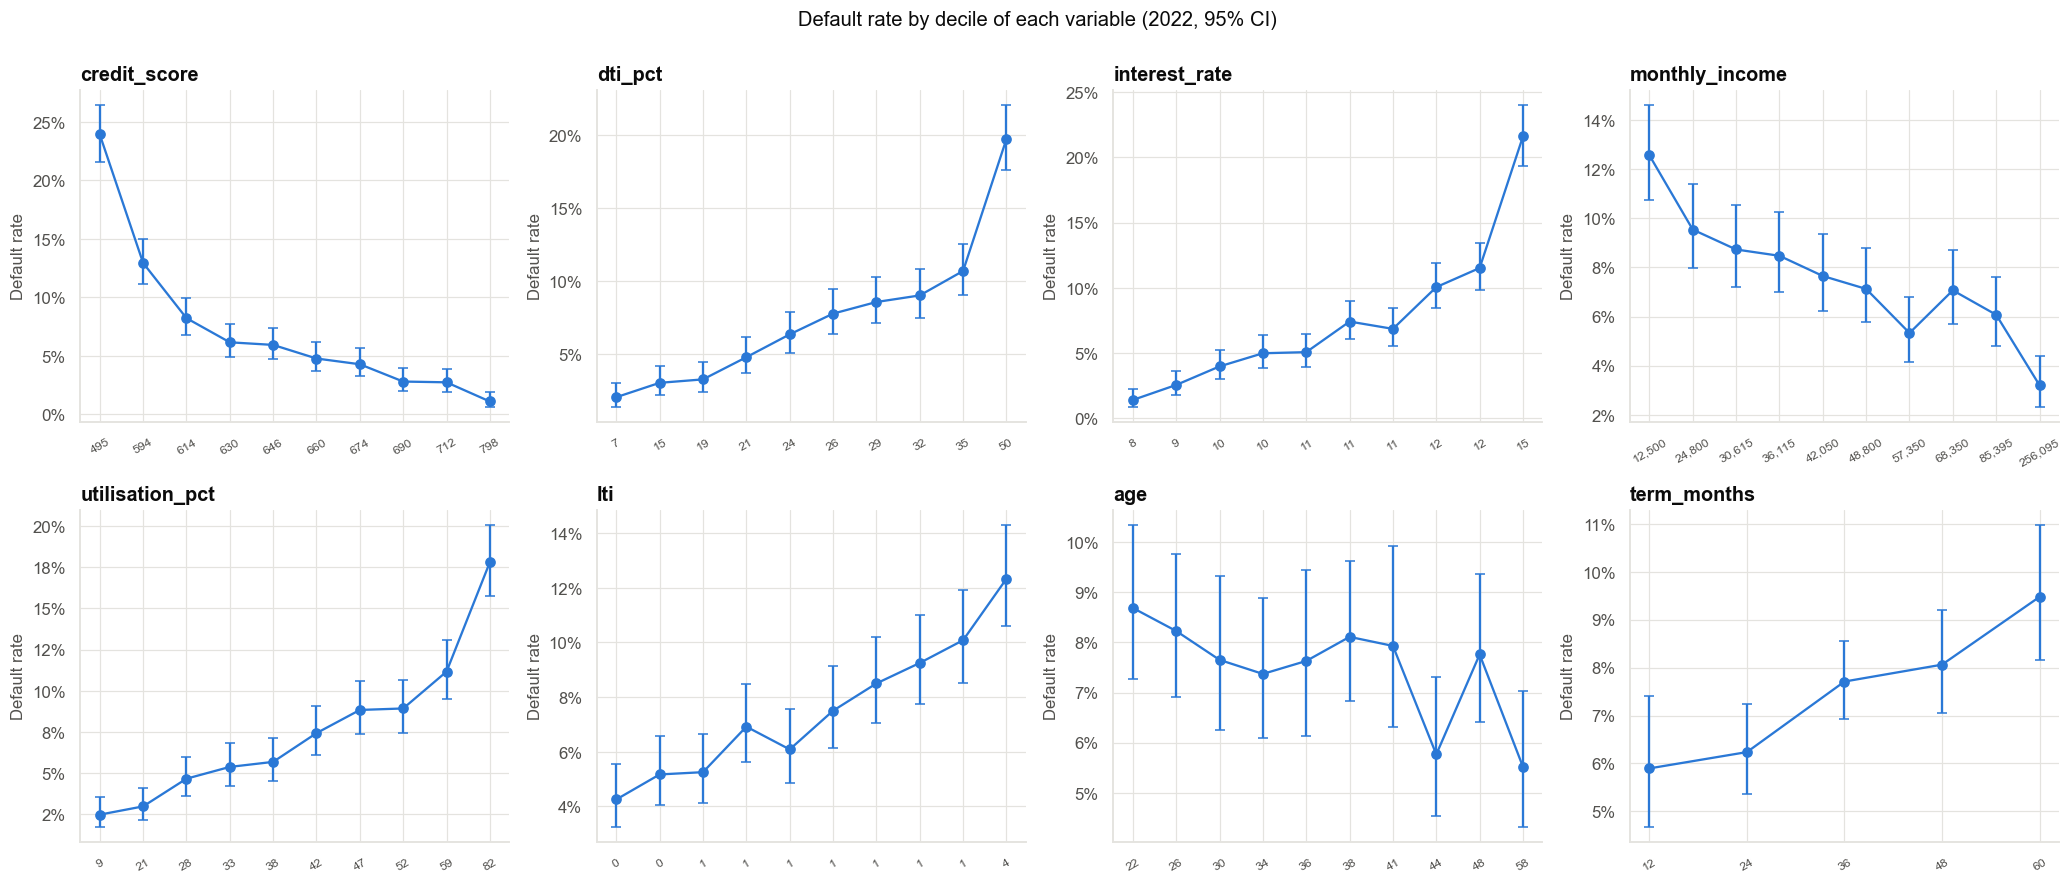

,variable,level,loans,default rate,ci_low,ci_high
0,channel,agent,2625,0.1135,0.1019,0.1262
1,channel,branch,4236,0.0654,0.0583,0.0732
2,channel,online,5139,0.0640,0.0576,0.0710
3,employment_type,gig,1228,0.1221,0.1050,0.1417
4,employment_type,salaried,8078,0.0649,0.0597,0.0704
5,employment_type,self_employed,2694,0.0854,0.0754,0.0965
6,prior_delinquency,0,10026,0.0555,0.0511,0.0601
7,prior_delinquency,1,1419,0.1438,0.1265,0.1630
8,prior_delinquency,2+,555,0.2595,0.2247,0.2975
9,city_tier,1,4801,0.0775,0.0703,0.0854


In [5]:
y = "defaulted_12m"
num = ["dti_pct", "credit_score", "interest_rate", "monthly_income", "loan_amount", "lti", "term_months", "utilisation_pct", "age", "years_in_job"]
fig, axes = plt.subplots(2, 4, figsize=(19, 8))
for ax, c in zip(axes.ravel(), ["credit_score", "dti_pct", "interest_rate", "monthly_income", "utilisation_pct", "lti", "age", "term_months"]):
    d = dev_all[[c, y]].dropna(); q = pd.qcut(d[c], 10, duplicates="drop") if d[c].nunique() > 10 else d[c]
    g = d.groupby(q, observed=True)[y].agg(["mean", "size", "sum"]); ci = np.array([wilson(k, n) for k, n in zip(g["sum"], g["size"])])
    ax.errorbar(range(len(g)), g["mean"], yerr=[g["mean"] - ci[:, 0], ci[:, 1] - g["mean"]], fmt="o-", color=PRIMARY, capsize=3)
    ax.set_xticks(range(len(g)), [f"{iv.mid:,.0f}" if hasattr(iv, "mid") else str(iv) for iv in g.index], fontsize=8, rotation=30)
    ax.yaxis.set_major_formatter(pctfmt); ax.set(title=c, ylabel="Default rate")
fig.suptitle("Default rate by decile of each variable (2022, 95% CI)", y=1.0); fig.tight_layout(); save_fig(fig, "fig01_default_by_decile", PATHS["figures"]); plt.show()
cat_rows = []
for c in ["channel", "employment_type", "prior_delinquency", "city_tier"]:
    g = dev_all.groupby(c)[y].agg(["mean", "size", "sum"])
    for lv, r in g.iterrows():
        lo, hi = wilson(r["sum"], r["size"]); cat_rows.append({"variable": c, "level": lv, "loans": int(r["size"]), "default rate": r["mean"], "ci_low": lo, "ci_high": hi})
cat = pd.DataFrame(cat_rows); save_table(cat, "default_by_category", PATHS["tables"], index=False); display(cat)

In [6]:
# Univariate tests with multiplicity control
rows = []
for c in ["dti_pct", "credit_score", "interest_rate", "monthly_income", "loan_amount", "lti", "term_months", "utilisation_pct", "age", "years_in_job"]:
    d = dev_all[[c, y]].dropna(); a, b = d[d[y] == 1][c], d[d[y] == 0][c]
    u, p = stats.mannwhitneyu(a, b); auc = u / (len(a) * len(b))
    rows.append({"variable": c, "type": "numeric", "defaulters median": a.median(), "non-defaulters median": b.median(), "AUC (0.5 = no signal)": auc, "p-value": p})
for c in ["channel", "employment_type", "prior_delinquency", "city_tier"]:
    ct = pd.crosstab(dev_all[c], dev_all[y]); chi2, p, _, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    rows.append({"variable": c, "type": "categorical", "defaulters median": np.nan, "non-defaulters median": np.nan, "AUC (0.5 = no signal)": np.nan, "p-value": p, "Cramér's V": v})
uni = pd.DataFrame(rows).set_index("variable")
uni["BH-adjusted p"] = multipletests(uni["p-value"], method="fdr_bh")[1]; uni["significant after BH (5%)"] = uni["BH-adjusted p"] < 0.05
uni["strength"] = np.where(uni["AUC (0.5 = no signal)"].notna(), (uni["AUC (0.5 = no signal)"] - 0.5).abs() + 0.5, np.nan)
save_table(uni, "univariate_tests", PATHS["tables"]); display(uni.drop(columns=["strength"]))

,type,defaulters median,non-defaulters median,AUC (0.5 = no signal),p-value,Cramér's V,BH-adjusted p,significant after BH (5%)
variable,,,,,,,,
dti_pct,numeric,30.7500,24.7000,0.6847,0.0000,NaN,0.0000,True
credit_score,numeric,604.5000,655.0000,0.2640,0.0000,NaN,0.0000,True
interest_rate,numeric,11.8700,10.6300,0.7062,0.0000,NaN,0.0000,True
monthly_income,numeric,"37,750.0000","45,900.0000",0.4080,0.0000,NaN,0.0000,True
loan_amount,numeric,"425,500.0000","427,000.0000",0.4999,0.9955,NaN,0.9955,False
lti,numeric,1.0460,0.8422,0.5971,0.0000,NaN,0.0000,True
term_months,numeric,36.0000,36.0000,0.5426,0.0000,NaN,0.0000,True
utilisation_pct,numeric,49.7500,39.5000,0.6655,0.0000,NaN,0.0000,True
age,numeric,36.0000,37.0000,0.4725,0.0059,NaN,0.0069,True


**Observation.** Default rises steadily with **debt-to-income, utilisation, loan-to-annual-income and prior delinquency** (5.6% with none, 14.4% with one, 26.0% with two or more), falls with the **credit score and income**, and is higher for **gig (12.2%) and self-employed (8.5%)** than salaried borrowers (6.5%).
Agent-channel loans default at **11.4% against 6.4% to 6.5%** for branch and online. City tier does nothing (p = 0.75). Loan amount alone carries no signal (AUC 0.500). Twelve of the 14 variables are significant after Benjamini-Hochberg correction;
by strength, the credit score (AUC 0.74 once oriented), interest rate (0.71), DTI (0.68) and utilisation (0.67) stand out; income (0.59) and age (0.53) are weak.

**Interpretation.** With 12,000 loans nearly everything is "significant", so significance does not rank anything: effect sizes (AUC, rates by decile) do. The interest rate looks like the second-best single predictor, and the dashboard's three claims
(agent, rate, income) are all visible here. The next section asks whether they survive adjustment.

## Section 7 — Do the dashboard's claims survive adjustment? Confounding and proxies

We fit each claim alone (the raw odds ratio) and then with the other relevant borrower variables (the adjusted odds ratio). If a variable's effect shrinks sharply, it was standing in for something else.
Control set: debt-to-income, credit score (plus thin-file indicator), prior delinquency, loan-to-annual-income, term, employment type, utilisation.

,raw OR,raw CI low,raw CI high,adjusted OR,adj CI low,adj CI high,adjusted p
claim,,,,,,,
agent channel (vs rest),1.8531,1.6014,2.1444,1.1452,0.9743,1.3460,0.1002
interest rate (+1 point),1.6367,1.5638,1.7129,1.0599,0.9751,1.1520,0.1714
"monthly income (+₹10,000)",0.8875,0.8633,0.9124,0.9840,0.9567,1.0121,0.2615
age (+10 years),0.8963,0.8340,0.9632,0.9967,0.9210,1.0787,0.9355


,default_rate,mean_score,mean_dti,prior_share,self_emp
agent,,,,,
0,0.0646,659.7722,24.5985,0.1555,0.2243
1,0.1135,626.7178,26.9590,0.1966,0.2251


Spearman correlation of the interest rate with the credit score: -0.84


,dti_pct,credit_score,interest_rate,income_f,loan_amount,lti,term_months,utilisation_pct,age_f
VIF,1.1790,4.3373,4.0142,5.5702,8.2880,3.9086,1.1227,1.2174,1.0556


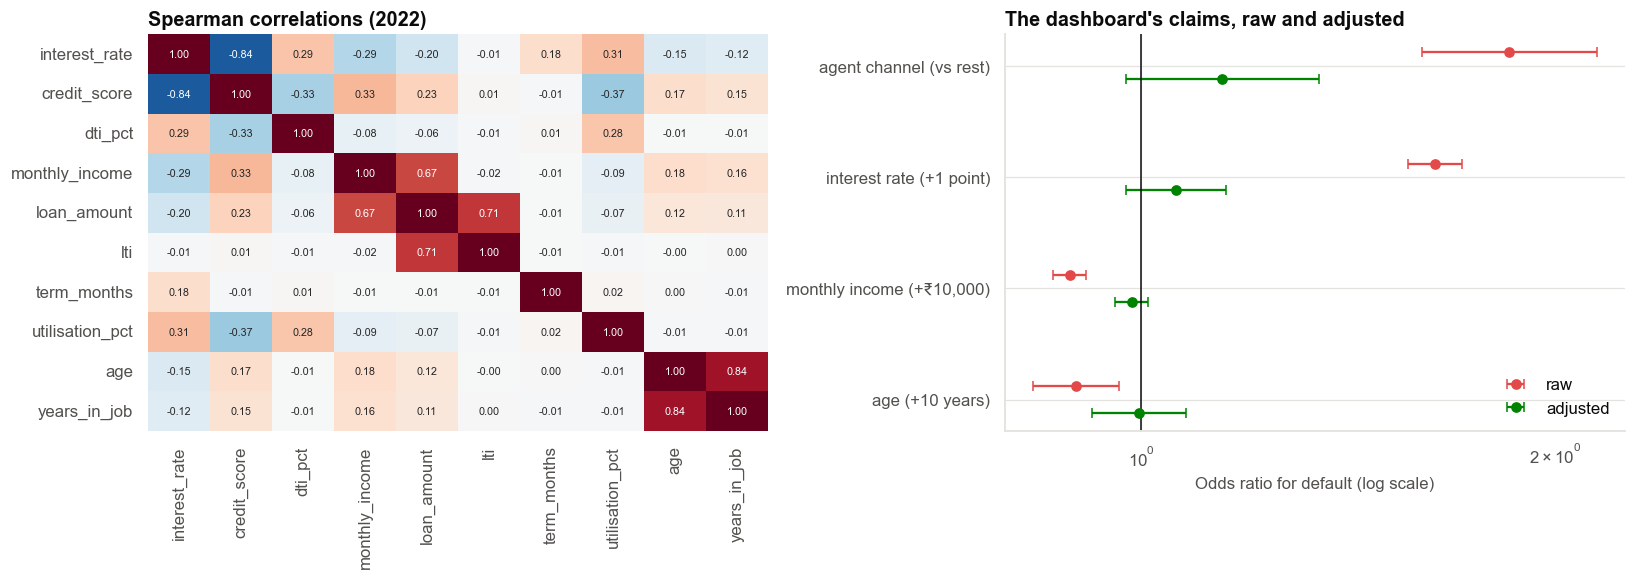

In [7]:
ctrl = "dti_pct + score_c + thin_file + C(prior) + lti + term_months + C(employment_type, Treatment('salaried')) + utilisation_pct"
claims = {
    "agent channel (vs rest)": ("agent", "agent"),
    "interest rate (+1 point)": ("interest_rate", "interest_rate"),
    "monthly income (+₹10,000)": ("I(income_f / 10000)", "I(income_f / 10000)"),
    "age (+10 years)": ("I(age_f / 10)", "I(age_f / 10)"),
}
rows = []
for lab, (term, key) in claims.items():
    m0 = smf.logit(f"{y} ~ {term}", dev_all).fit(disp=0); m1 = smf.logit(f"{y} ~ {term} + {ctrl}", dev_all).fit(disp=0)
    c0, c1 = m0.params[term], m1.params[term]; ci0, ci1 = m0.conf_int().loc[term], m1.conf_int().loc[term]
    rows.append({"claim": lab, "raw OR": np.exp(c0), "raw CI low": np.exp(ci0[0]), "raw CI high": np.exp(ci0[1]), "adjusted OR": np.exp(c1), "adj CI low": np.exp(ci1[0]), "adj CI high": np.exp(ci1[1]), "adjusted p": m1.pvalues[term]})
claims_tbl = pd.DataFrame(rows).set_index("claim"); save_table(claims_tbl, "claims_raw_vs_adjusted", PATHS["tables"]); display(claims_tbl)
ag = dev_all.groupby("agent").agg(default_rate=(y, "mean"), mean_score=("credit_score", "mean"), mean_dti=("dti_pct", "mean"), prior_share=("prior", lambda s: (s > 0).mean()), self_emp=("employment_type", lambda s: (s == "self_employed").mean()))
save_table(ag, "agent_vs_other_profile", PATHS["tables"]); display(ag)
cm = dev_all[["interest_rate", "credit_score", "dti_pct", "monthly_income", "loan_amount", "lti", "term_months", "utilisation_pct", "age", "years_in_job"]].corr(method="spearman")
print("Spearman correlation of the interest rate with the credit score:", round(cm.loc["interest_rate", "credit_score"], 2))
Xv = dev_all[["dti_pct", "credit_score", "interest_rate", "income_f", "loan_amount", "lti", "term_months", "utilisation_pct", "age_f"]].dropna()
Xv = sm.add_constant(Xv); vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])], index=Xv.columns[1:], name="VIF")
save_table(vif.to_frame(), "vif_all_candidates", PATHS["tables"]); display(vif.to_frame().T)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[0], cbar=False, annot_kws={"size": 7}); axes[0].set_title("Spearman correlations (2022)")
ax = axes[1]; cl = claims_tbl.iloc[::-1]
for i, (k, r) in enumerate(cl.iterrows()):
    ax.errorbar(r["raw OR"], i + 0.12, xerr=[[r["raw OR"] - r["raw CI low"]], [r["raw CI high"] - r["raw OR"]]], fmt="o", color=COLORS["red"], capsize=3, label="raw" if i == 0 else None)
    ax.errorbar(r["adjusted OR"], i - 0.12, xerr=[[r["adjusted OR"] - r["adj CI low"]], [r["adj CI high"] - r["adjusted OR"]]], fmt="o", color=COLORS["green"], capsize=3, label="adjusted" if i == 0 else None)
ax.axvline(1, color=INK, lw=1); ax.set_yticks(range(len(cl)), cl.index); ax.set_xscale("log"); ax.set(xlabel="Odds ratio for default (log scale)", title="The dashboard's claims, raw and adjusted"); ax.legend(frameon=False)
fig.tight_layout(); save_fig(fig, "fig02_claims_raw_vs_adjusted", PATHS["figures"]); plt.show()

**Observation.** Raw and adjusted odds ratios (adjusted for DTI, credit score, thin-file flag, prior delinquency, loan-to-income, term, employment and utilisation):

| Claim | Raw OR | Adjusted OR |
|---|---|---|
| Agent channel | **1.85** (1.60 to 2.14) | **1.15** (0.97 to 1.35) |
| Interest rate, +1 point | **1.64** (1.56 to 1.71) | **1.06** (0.98 to 1.15) |
| Income, +₹10,000 | **0.89** (0.86 to 0.91) | **0.98** (0.96 to 1.01) |
| Age, +10 years | **0.90** (0.83 to 0.96) | **1.00** (0.92 to 1.08) |

Agent-channel borrowers have a **mean credit score of 627 against 660** and a higher share of prior delinquency (19.7% against 15.6%): the channel attracts weaker borrowers. The interest rate has a **Spearman correlation of −0.84 with the credit score**: it is the score, repriced.
VIFs are moderate (credit score 4.3, interest rate 4.0, income 5.6) but the loan amount, which equals loan-to-income times income, is at 8.3.

**Interpretation.** All three claims on the dashboard shrink to roughly nothing once we compare like with like. The **agent channel is a proxy for lower scores** (a small residual effect cannot be ruled out, p = 0.10); the **interest rate is a repriced credit score** and has no separate effect; **income and age work through DTI, loan size and the score**.
Stopping agent lending, raising the minimum income or pricing harder on rate would all act on symptoms.

## Section 8 — Model selection: a final logistic model and a "kitchen-sink" alternative

**Final model (chosen by reasoning, not by p-values):** debt-to-income, credit score (centred at 650) with a thin-file indicator, prior delinquency, loan-to-annual-income, term, employment type, utilisation and channel.
We **leave out the interest rate** (it is set from the credit score, so it adds redundancy and would not be available as an independent lever) and **city tier**. We keep income only through loan-to-income and DTI.

**Kitchen-sink model:** everything, including interest rate, age, log income, loan amount, city tier.

We compare them on information criteria and a likelihood-ratio test, then on out-of-sample metrics. Selection and fitting use only the 2022 fit sample.

In [8]:
f_final = f"{y} ~ dti_pct + score_c + thin_file + C(prior) + lti + term_months + C(employment_type, Treatment('salaried')) + utilisation_pct + C(channel, Treatment('branch'))"
f_ks = f_final + " + interest_rate + age_f + np.log(income_f) + I(loan_amount / 100000) + C(city_tier)"
m_final = smf.logit(f_final, tr).fit(disp=0); m_ks = smf.logit(f_ks, tr).fit(disp=0)
lr = 2 * (m_ks.llf - m_final.llf); dfd = m_ks.df_model - m_final.df_model
print(f"Final: AIC {m_final.aic:.0f}, BIC {m_final.bic:.0f}, pseudo-R2 {m_final.prsquared:.3f};  Kitchen sink: AIC {m_ks.aic:.0f}, BIC {m_ks.bic:.0f}, pseudo-R2 {m_ks.prsquared:.3f}")
print(f"Likelihood-ratio test of the {int(dfd)} extra terms: chi-square {lr:.1f}, p = {fmt_p(stats.chi2.sf(lr, dfd))}")
ci = np.exp(m_final.conf_int()); or_tbl = pd.DataFrame({"coefficient": m_final.params, "odds ratio": np.exp(m_final.params), "ci_low": ci[0], "ci_high": ci[1], "p-value": m_final.pvalues})
or_tbl.index = [i.replace("C(employment_type, Treatment('salaried'))", "emp").replace("C(channel, Treatment('branch'))", "channel").replace("C(prior)", "prior") for i in or_tbl.index]
save_table(or_tbl, "final_model_odds_ratios", PATHS["tables"]); display(or_tbl)
ks_ci = np.exp(m_ks.conf_int()); ks_tbl = pd.DataFrame({"odds ratio": np.exp(m_ks.params), "ci_low": ks_ci[0], "ci_high": ks_ci[1], "p-value": m_ks.pvalues})
ks_tbl.index = [i.replace("C(employment_type, Treatment('salaried'))", "emp").replace("C(channel, Treatment('branch'))", "channel").replace("C(prior)", "prior") for i in ks_tbl.index]
save_table(ks_tbl, "kitchen_sink_odds_ratios", PATHS["tables"]); display(ks_tbl.loc[[i for i in ks_tbl.index if i in ("interest_rate", "age_f", "np.log(income_f)", "I(loan_amount / 100000)", "score_c", "channel[T.agent]") or i.startswith("C(city")]])

Final: AIC 4044, BIC 4136, pseudo-R2 0.179;  Kitchen sink: AIC 4054, BIC 4189, pseudo-R2 0.180
Likelihood-ratio test of the 6 extra terms: chi-square 2.0, p = 0.920


,coefficient,odds ratio,ci_low,ci_high,p-value
Intercept,-6.1451,0.0021,0.0013,0.0035,0.0000
prior[T.1],0.5447,1.7242,1.3913,2.1367,0.0000
prior[T.2],1.4145,4.1145,3.1702,5.3400,0.0000
emp[T.gig],0.7725,2.1652,1.6992,2.7590,0.0000
emp[T.self_employed],0.3444,1.4112,1.1580,1.7198,0.0006
channel[T.agent],0.1208,1.1284,0.9093,1.4002,0.2729
channel[T.online],-0.0029,0.9971,0.8153,1.2195,0.9778
dti_pct,0.0454,1.0465,1.0363,1.0567,0.0000
score_c,-0.0112,0.9888,0.9870,0.9907,0.0000
thin_file,0.6884,1.9906,1.4526,2.7278,0.0000


,odds ratio,ci_low,ci_high,p-value
channel[T.agent],1.1241,0.9055,1.3953,0.2891
C(city_tier)[T.2],0.9197,0.7582,1.1156,0.3957
C(city_tier)[T.3],0.9548,0.7717,1.1812,0.6700
score_c,0.9896,0.9866,0.9926,0.0000
interest_rate,1.0189,0.9254,1.1217,0.7034
age_f,0.9978,0.9887,1.0070,0.6396
np.log(income_f),0.9212,0.6956,1.2200,0.5670
I(loan_amount / 100000),1.0020,0.9615,1.0443,0.9229


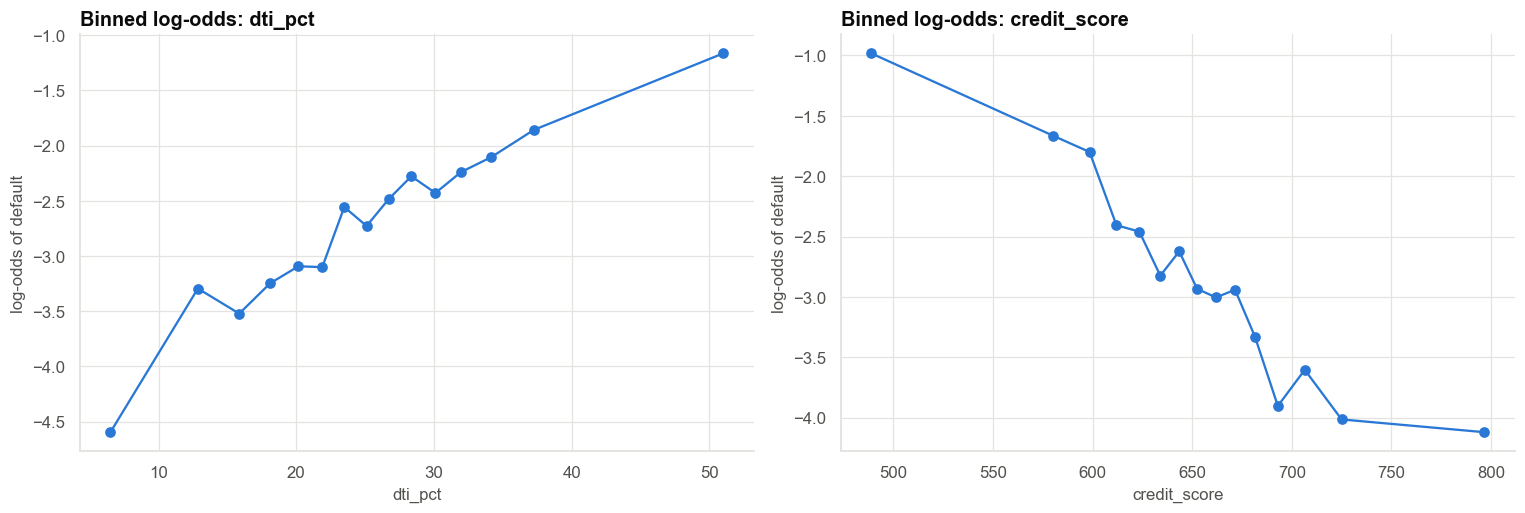

Adding squared DTI and squared score: LR chi-square 1.3 on 2 df, p = 0.533  (a small p would call for a curve)


,change in default probability (pp),baseline default rate (pp)
DTI +10 points,3.2470,7.7222
credit score +50,-2.8585,7.7222
prior delinquency 0 to 1,2.2243,7.7222
loan-to-annual-income +0.5,2.6328,7.7222
term +12 months,0.7609,7.7222
utilisation +20 points,1.9758,7.7222
self-employed (vs salaried),1.0754,7.7222
gig (vs salaried),4.4641,7.7222
agent channel (vs branch),0.5448,7.7222


In [9]:
# Linearity of the log-odds in the two strongest continuous drivers: binned log-odds and a spline likelihood-ratio test
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, c in zip(axes, ["dti_pct", "credit_score"]):
    d = tr[[c, y]].dropna(); q = pd.qcut(d[c], 15, duplicates="drop"); g = d.groupby(q, observed=True)[y].agg(["mean", "size"]); lo = np.log(g["mean"] / (1 - g["mean"]))
    ax.plot([iv.mid for iv in g.index], lo, "o-", color=PRIMARY); ax.set(xlabel=c, ylabel="log-odds of default", title=f"Binned log-odds: {c}")
fig.tight_layout(); save_fig(fig, "fig03_linearity", PATHS["figures"]); plt.show()
f_sp = f_final + " + I(dti_pct ** 2) + I(score_c ** 2)"
m_sp = smf.logit(f_sp, tr).fit(disp=0); lr_sp = 2 * (m_sp.llf - m_final.llf)
print(f"Adding squared DTI and squared score: LR chi-square {lr_sp:.1f} on 2 df, p = {fmt_p(stats.chi2.sf(lr_sp, 2))}  (a small p would call for a curve)")
# Marginal effects: change in predicted default probability, averaged over the fit sample
def ame(model, d, change):
    base = model.predict(d).mean(); alt = d.copy(); change(alt); return 100 * (model.predict(alt).mean() - base)
effects = {
    "DTI +10 points": lambda a: a.__setitem__("dti_pct", a.dti_pct + 10),
    "credit score +50": lambda a: a.__setitem__("score_c", a.score_c + 50),
    "prior delinquency 0 to 1": lambda a: a.__setitem__("prior", 1),
    "loan-to-annual-income +0.5": lambda a: a.__setitem__("lti", a.lti + 0.5),
    "term +12 months": lambda a: a.__setitem__("term_months", a.term_months + 12),
    "utilisation +20 points": lambda a: a.__setitem__("utilisation_pct", a.utilisation_pct + 20),
    "self-employed (vs salaried)": lambda a: a.__setitem__("employment_type", "self_employed"),
    "gig (vs salaried)": lambda a: a.__setitem__("employment_type", "gig"),
    "agent channel (vs branch)": lambda a: a.__setitem__("channel", "agent"),
}
me = pd.DataFrame({"change in default probability (pp)": {k: ame(m_final, tr, f) for k, f in effects.items()}})
me["baseline default rate (pp)"] = 100 * m_final.predict(tr).mean()
save_table(me, "marginal_effects", PATHS["tables"]); display(me)

**Observation.** The final model has a pseudo-R² of 0.179 and AIC 4,044. The kitchen-sink model, which adds interest rate, age, log income, loan amount and city tier, has **AIC 4,054 and no significant improvement** (likelihood-ratio χ² = 2.0 on 6 df, p = 0.92); none of its extra terms is distinguishable from zero.
Odds ratios in the final model: **prior delinquency 1.7 (one) and 4.1 (two or more)**, **gig 2.2**, self-employed 1.4, **loan-to-annual-income 2.1 per unit**, thin file 2.0, DTI 1.047 per point (1.6 per 10 points), credit score 0.989 per point (0.57 per 50 points), utilisation 1.015 per point, term 1.010 per month.
The agent channel is 1.13 (0.91 to 1.40, p = 0.27). Adding squared DTI and squared score does not help (p = 0.53): the log-odds are close to linear in both.

Effect on the default probability (baseline 7.7%): **DTI +10 points +3.2 pp**, **credit score +50 −2.9 pp**, prior delinquency 0 to 1 +2.2 pp, loan-to-income +0.5 +2.6 pp, utilisation +20 points +2.0 pp, term +12 months +0.8 pp, self-employed +1.1 pp, **gig +4.5 pp**, **agent channel +0.5 pp**.

**Interpretation.** The drivers are the affordability and track-record variables: DTI, loan size relative to income, utilisation, prior delinquency, the credit score and the employment type. Odds ratios are right for the model statement; percentage-point changes are the right language for the business.

## Section 9 — Validation: discrimination, calibration and stability out of time

Metrics on the internal 2022 validation sample and the 2023 out-of-time sample: **AUC** (ranking), **PR-AUC** (precision/recall at a 7.5% base rate), **KS**, **Brier score**, and calibration (slope and intercept of the observed outcome on the log-odds of the prediction;
a perfectly calibrated model has slope 1 and intercept 0). We also compute the **population stability index (PSI)** of the credit score and the channel mix.

,loans,default rate,mean predicted,AUC,PR-AUC,KS,Brier,calibration slope,calibration intercept,AUC low,AUC high
sample,,,,,,,,,,,
final: fit sample (2022),9000,0.0772,0.0772,0.7989,0.3280,0.4651,0.0612,1.0000,-0.0000,NaN,NaN
final: internal validation (2022),3000,0.0697,0.0775,0.7875,0.2644,0.4621,0.0581,0.9415,-0.2484,0.7542,0.8134
final: out-of-time (2023),12000,0.0738,0.0772,0.7927,0.2944,0.4432,0.0600,0.9579,-0.1398,0.7768,0.8078
kitchen sink: internal validation (2022),3000,0.0697,0.0777,0.7871,0.2633,0.4585,0.0581,0.9359,-0.2620,0.7519,0.8173
kitchen sink: out-of-time (2023),12000,0.0738,0.0772,0.7927,0.2951,0.4473,0.0600,0.9588,-0.1370,0.7788,0.8087
"score only (credit score alone), out-of-time",12000,0.0738,NaN,0.7255,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,2022,2023,PSI
mean credit score,652.5252,653.7499,0.0027
agent share,0.2188,0.2903,NaN
mean DTI,25.1149,24.9918,0.0011
default rate,0.0753,0.0738,NaN


,loans,predicted,observed,defaults,ci_low,ci_high
decile,,,,,,
1,1200,0.0064,0.0108,13,0.0063,0.0184
2,1200,0.0129,0.0150,18,0.0095,0.0236
3,1200,0.0195,0.0208,25,0.0142,0.0306
4,1200,0.0270,0.0233,28,0.0162,0.0335
5,1200,0.0365,0.0408,49,0.0310,0.0536
6,1200,0.0490,0.0367,44,0.0274,0.0489
7,1200,0.0665,0.0708,85,0.0576,0.0868
8,1200,0.0933,0.0883,106,0.0736,0.1057
9,1200,0.1444,0.1308,157,0.1129,0.1511


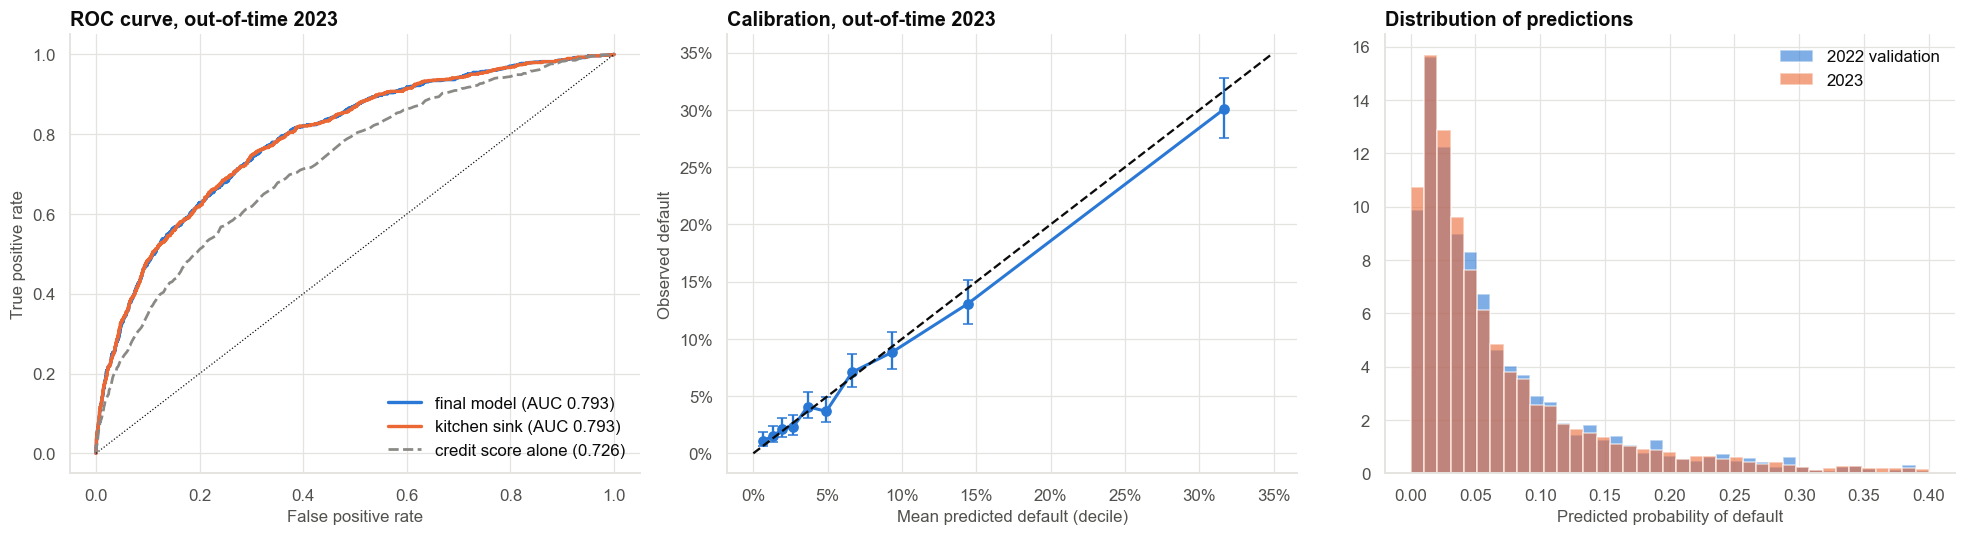

In [10]:
def metrics(model, d, label, boot=0):
    p = model.predict(d).to_numpy(); yy = d[y].to_numpy()
    fpr, tpr, _ = roc_curve(yy, p); ks = np.max(tpr - fpr)
    lg = np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
    cal = sm.Logit(yy, sm.add_constant(lg)).fit(disp=0)
    out = {"sample": label, "loans": len(d), "default rate": yy.mean(), "mean predicted": p.mean(), "AUC": roc_auc_score(yy, p), "PR-AUC": average_precision_score(yy, p), "KS": ks,
           "Brier": brier_score_loss(yy, p), "calibration slope": cal.params[1], "calibration intercept": cal.params[0]}
    if boot:
        bs = []
        for _ in range(boot):
            ix = rng.integers(0, len(yy), len(yy)); bs.append(roc_auc_score(yy[ix], p[ix]))
        out["AUC low"], out["AUC high"] = np.percentile(bs, [2.5, 97.5])
    return out
rows = [metrics(m_final, tr, "final: fit sample (2022)"), metrics(m_final, va, "final: internal validation (2022)", 300), metrics(m_final, oot, "final: out-of-time (2023)", 300),
        metrics(m_ks, va, "kitchen sink: internal validation (2022)", 300), metrics(m_ks, oot, "kitchen sink: out-of-time (2023)", 300)]
rows.append({"sample": "score only (credit score alone), out-of-time", "loans": len(oot), "default rate": oot[y].mean(), "AUC": roc_auc_score(oot[y], -oot.credit_score.fillna(650))})
met = pd.DataFrame(rows).set_index("sample"); save_table(met, "validation_metrics", PATHS["tables"]); display(met)
def psi(a, b, bins=10):
    edges = np.quantile(a.dropna(), np.linspace(0, 1, bins + 1)); edges[0], edges[-1] = -np.inf, np.inf
    pa = np.histogram(a.dropna(), edges)[0] / a.notna().sum(); pb = np.histogram(b.dropna(), edges)[0] / b.notna().sum()
    return np.sum((pb - pa) * np.log((pb + 1e-6) / (pa + 1e-6)))
drift = pd.DataFrame({"2022": [dev_all.credit_score.mean(), dev_all.agent.mean(), dev_all.dti_pct.mean(), dev_all[y].mean()], "2023": [oot.credit_score.mean(), oot.agent.mean(), oot.dti_pct.mean(), oot[y].mean()]},
                     index=["mean credit score", "agent share", "mean DTI", "default rate"])
drift["PSI"] = [psi(dev_all.credit_score, oot.credit_score), np.nan, psi(dev_all.dti_pct, oot.dti_pct), np.nan]
save_table(drift, "drift_2022_vs_2023", PATHS["tables"]); display(drift)
# Calibration by decile of predicted risk, out of time
oot["p"] = m_final.predict(oot); oot["decile"] = pd.qcut(oot.p, 10, labels=False) + 1
cal_tbl = oot.groupby("decile").agg(loans=("p", "size"), predicted=("p", "mean"), observed=(y, "mean"), defaults=(y, "sum"))
cal_tbl[["ci_low", "ci_high"]] = [wilson(k, n) for k, n in zip(cal_tbl.defaults, cal_tbl.loans)]
save_table(cal_tbl, "calibration_by_decile_oot", PATHS["tables"]); display(cal_tbl)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ax = axes[0]
for mdl, lab, c in [(m_final, "final model", PRIMARY), (m_ks, "kitchen sink", COLORS["orange"])]:
    fpr, tpr, _ = roc_curve(oot[y], mdl.predict(oot)); ax.plot(fpr, tpr, color=c, lw=2.2, label=f"{lab} (AUC {roc_auc_score(oot[y], mdl.predict(oot)):.3f})")
fpr, tpr, _ = roc_curve(oot[y], -oot.credit_score.fillna(650)); ax.plot(fpr, tpr, color=INK_MUTED, lw=1.8, ls="--", label=f"credit score alone ({roc_auc_score(oot[y], -oot.credit_score.fillna(650)):.3f})")
ax.plot([0, 1], [0, 1], color=INK, lw=0.8, ls=":"); ax.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve, out-of-time 2023"); ax.legend(frameon=False, loc="lower right")
ax = axes[1]; ax.plot(cal_tbl.predicted, cal_tbl.observed, "o-", color=PRIMARY, lw=2); ax.errorbar(cal_tbl.predicted, cal_tbl.observed, yerr=[cal_tbl.observed - cal_tbl.ci_low, cal_tbl.ci_high - cal_tbl.observed], fmt="none", color=PRIMARY, capsize=3)
mx = max(cal_tbl.predicted.max(), cal_tbl.observed.max()) * 1.1; ax.plot([0, mx], [0, mx], color=INK, ls="--"); ax.xaxis.set_major_formatter(pctfmt); ax.yaxis.set_major_formatter(pctfmt)
ax.set(xlabel="Mean predicted default (decile)", ylabel="Observed default", title="Calibration, out-of-time 2023")
ax = axes[2]
ax.hist(m_final.predict(va), bins=np.linspace(0, 0.4, 40), alpha=0.6, color=PRIMARY, label="2022 validation", density=True); ax.hist(oot.p, bins=np.linspace(0, 0.4, 40), alpha=0.6, color=COLORS["orange"], label="2023", density=True)
ax.set(xlabel="Predicted probability of default", title="Distribution of predictions"); ax.legend(frameon=False)
fig.tight_layout(); save_fig(fig, "fig04_validation", PATHS["figures"]); plt.show()

**Observation.** Out-of-time (2023, 12,000 loans, never used for fitting): **AUC 0.793** (95% CI 0.777 to 0.808), PR-AUC 0.29 (against a base rate of 7.4%), KS 0.44, Brier 0.060, **calibration slope 0.96**, intercept −0.14 (the model slightly over-predicts, mean predicted 7.7% against 7.4% observed).
On the 2022 internal validation sample the AUC was 0.787, so the out-of-time result is consistent. The credit score alone has an AUC of 0.726: the model adds about 7 points. The kitchen-sink model is identical (0.793).
Drift is small: the credit score PSI is 0.003 and the DTI PSI 0.001, although the **agent share rose from 21.9% to 29.0%**. Calibration by decile is close: the highest-risk decile has 30.1% observed against 31.7% predicted, the lowest 1.1% against 0.6% (the interval touches the prediction).

**Interpretation.** The model ranks well (AUC about 0.79), is nearly calibrated, and held up in a later year with more agent business, which is what we expect when agent borrowers are explained by their scores and not by the channel itself.
A slope below 1 means the predictions are a little too spread out: apply a shrinkage or recalibrate before using absolute probabilities for pricing.

## Section 10 — From probability to decision: approval policy

Assumptions for Finance to change: a performing loan earns **₹6,000** of margin over its life; a default loses **₹60,000** net of recoveries. Approving a loan with default probability p pays when
(1 − p) × 6,000 − p × 60,000 > 0, i.e. **p < 9.1%**. We compare policies on the 2023 out-of-time sample with the actual outcomes: approve all; approve credit score ≥ 650 (a typical rule of thumb); the model with the theoretical cut-off; and
a policy that rejects agent-channel loans (the dashboard's proposal).

,approval rate,default rate among approved,expected profit per application (₹),total profit (₹ lakh)
Approve all,1.0000,0.0738,"1,127.0000",135.2400
Reject the agent channel (dashboard proposal),0.7097,0.0569,"1,591.0000",190.9200
Credit score at least 650,0.5062,0.0318,"1,975.5000",237.0600
Model: approve if predicted PD below 9.1%,0.7463,0.0344,"2,784.0000",334.0800
Model: approve if PD below 6%,0.6202,0.0262,"2,648.5000",317.8200
Model: approve if PD below 12%,0.8159,0.0391,"2,789.0000",334.6800


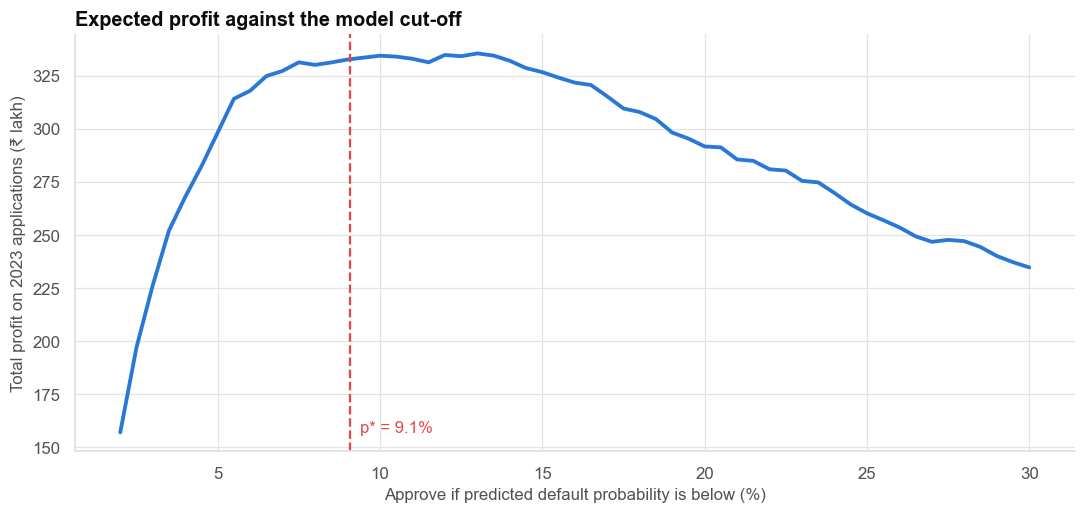

Best cut-off on this sample: 13.0% (theory says 9.1%); profit 335.4 lakh versus approve-all 135.2 lakh


In [11]:
PROFIT, LOSS = 6_000, 60_000
p_star = PROFIT / (PROFIT + LOSS)
oot["p"] = m_final.predict(oot); n_ = len(oot)
def policy_value(approve):
    a = oot[approve]; return {"approval rate": len(a) / n_, "default rate among approved": a[y].mean(), "expected profit per application (₹)": (((1 - a[y]) * PROFIT - a[y] * LOSS).sum()) / n_,
                              "total profit (₹ lakh)": (((1 - a[y]) * PROFIT - a[y] * LOSS).sum()) / 1e5}
pols = {"Approve all": oot.p >= 0,
        "Reject the agent channel (dashboard proposal)": oot.channel != "agent",
        "Credit score at least 650": oot.credit_score.fillna(0) >= 650,
        f"Model: approve if predicted PD below {p_star:.1%}": oot.p < p_star}
for t in [0.06, 0.12]:
    pols[f"Model: approve if PD below {t:.0%}"] = oot.p < t
pol = pd.DataFrame({k: policy_value(v) for k, v in pols.items()}).T
save_table(pol, "policy_comparison", PATHS["tables"]); display(pol)
grid = np.linspace(0.02, 0.30, 57)
gv = [policy_value(oot.p < t)["total profit (₹ lakh)"] for t in grid]
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(100 * grid, gv, color=PRIMARY, lw=2.5); ax.axvline(100 * p_star, color=COLORS["red"], ls="--"); ax.text(100 * p_star + 0.3, min(gv), f"p* = {p_star:.1%}", color=COLORS["red"])
ax.set(xlabel="Approve if predicted default probability is below (%)", ylabel="Total profit on 2023 applications (₹ lakh)", title="Expected profit against the model cut-off")
fig.tight_layout(); save_fig(fig, "fig05_profit_vs_cutoff", PATHS["figures"]); plt.show()
best_t = grid[int(np.argmax(gv))]; print(f"Best cut-off on this sample: {best_t:.1%} (theory says {p_star:.1%}); profit {max(gv):,.1f} lakh versus approve-all {pol.iloc[0]['total profit (₹ lakh)']:,.1f} lakh")

**Observation.** On the 2023 loans, with a ₹6,000 margin per good loan and a ₹60,000 loss per default (cut-off 9.1%):

| Policy | Approval rate | Default rate of approved | Profit per application | Total profit |
|---|---|---|---|---|
| Approve all | 100% | 7.4% | ₹1,127 | ₹135 lakh |
| Reject the agent channel (dashboard) | 71% | 5.7% | ₹1,591 | ₹191 lakh |
| Credit score at least 650 | 51% | 3.2% | ₹1,976 | ₹237 lakh |
| **Model, approve if PD below 9.1%** | **75%** | **3.4%** | **₹2,784** | **₹334 lakh** |
| Model, PD below 6% | 62% | 2.6% | ₹2,649 | ₹318 lakh |
| Model, PD below 12% | 82% | 3.9% | ₹2,789 | ₹335 lakh |

Profit is flat between 9% and 13% (the best on this sample is 13.0%, ₹335 lakh).

**Interpretation.** The model-based policy earns **₹199 lakh more than approving everyone**, ₹143 lakh more than the dashboard's agent ban and ₹97 lakh more than a score cut-off of 650, while approving 75% of applicants (the score rule approves only half).
The agent ban helps only because the agents' borrowers are weaker: a model policy removes the same bad loans (and others) without turning away good agent customers. The result depends on the stated margin and loss; the profit curve is flat near the optimum, so the cut-off is not delicate.

## Section 11 — Decision framework: from data to recommendation

| Step | Question | Tool used here |
|---|---|---|
| Define | What exactly is the outcome, and for whom is it observed? | 12-month default, loans with full history |
| Clean | Duplicates, labels, impossible values, missingness mechanism | Profiling, missingness tables, indicator + imputation |
| Explore | Shape, rates by decile, univariate signal with multiplicity control | Decile plots, AUC / chi-square, Benjamini-Hochberg |
| Challenge | Do raw patterns survive adjustment? Which variables are proxies? | Raw vs adjusted odds ratios, VIF, LR tests |
| Model | An interpretable, defensible specification | Logistic regression, odds ratios, marginal effects |
| Validate | Out of sample, out of time, calibrated? stable? | AUC, KS, calibration, PSI |
| Decide | Which action pays at the model's probabilities? | Cost-based cut-off |
| Communicate | What can and cannot be claimed | Language of association; limitations |

## Section 12 — Grading against the truth (answer key)

In [12]:
key = pd.read_csv(PATHS["data"] / "answer_key_coefficients.csv").set_index("term")["true_logit_coefficient"]
pk = pd.read_csv(PATHS["data"] / "answer_key_teaching_only.csv").drop_duplicates("loan_id").set_index("loan_id")["true_p"]
est = m_final.params; ci_ = m_final.conf_int()
mapping = {"dti_pct": "dti_pct", "score_c": "credit_score", "C(prior)[T.1]": "prior_delinquency", "lti": "loan_to_annual_income", "term_months": "term_months",
           "C(employment_type, Treatment('salaried'))[T.self_employed]": "self_employed", "C(employment_type, Treatment('salaried'))[T.gig]": "gig", "utilisation_pct": "utilisation_pct",
           "C(channel, Treatment('branch'))[T.agent]": "agent_channel", "thin_file": "thin_file"}
rows = []
for k, t in mapping.items():
    rows.append({"term": t, "true coefficient": key[t], "estimate": est[k], "ci_low": ci_.loc[k, 0], "ci_high": ci_.loc[k, 1], "CI covers truth": bool(ci_.loc[k, 0] <= key[t] <= ci_.loc[k, 1])})
cg = pd.DataFrame(rows).set_index("term"); save_table(cg, "coefficient_recovery", PATHS["tables"]); display(cg)
print(f"{int(cg['CI covers truth'].sum())} of {len(cg)} final-model coefficients have a 95% CI containing the truth")
ks_check = pd.DataFrame({"true effect": [0.0, 0.0, 0.0], "estimate": [m_ks.params["interest_rate"], m_ks.params["age_f"], m_ks.params["np.log(income_f)"]],
                         "ci_low": [m_ks.conf_int().loc[k, 0] for k in ["interest_rate", "age_f", "np.log(income_f)"]], "ci_high": [m_ks.conf_int().loc[k, 1] for k in ["interest_rate", "age_f", "np.log(income_f)"]]},
                        index=["interest rate (per point)", "age (per year)", "log income"])
ks_check["CI contains zero"] = (ks_check.ci_low <= 0) & (ks_check.ci_high >= 0)
save_table(ks_check, "noise_variables_in_kitchen_sink", PATHS["tables"]); display(ks_check)
oot["true_p"] = oot.loan_id.map(pk)
print(f"AUC ceiling on 2023 (using the TRUE probabilities): {roc_auc_score(oot[y], oot.true_p):.3f};  final model {roc_auc_score(oot[y], oot.p):.3f};  kitchen sink {roc_auc_score(oot[y], m_ks.predict(oot)):.3f};  credit score alone {roc_auc_score(oot[y], -oot.credit_score.fillna(650)):.3f}")
print(f"Mean true probability 2023 {oot.true_p.mean():.4f} vs mean predicted {oot.p.mean():.4f}; mean absolute error of the predicted probability {np.mean(np.abs(oot.p - oot.true_p)):.4f}")
true_pol = ((oot.true_p * (-LOSS) + (1 - oot.true_p) * PROFIT))
print(f"Policy using the TRUE probabilities (p < {p_star:.1%}): total expected profit {true_pol[oot.true_p < p_star].sum() / 1e5:,.1f} lakh vs model {pol.iloc[3]['total profit (₹ lakh)']:,.1f} lakh (realised)")

,true coefficient,estimate,ci_low,ci_high,CI covers truth
term,,,,,
dti_pct,0.0450,0.0454,0.0356,0.0552,True
credit_score,-0.0125,-0.0112,-0.0131,-0.0094,True
prior_delinquency,0.5500,0.5447,0.3302,0.7592,True
loan_to_annual_income,0.9000,0.7552,0.5878,0.9227,True
term_months,0.0120,0.0099,0.0039,0.0159,True
self_employed,0.4500,0.3444,0.1467,0.5422,True
gig,0.7000,0.7725,0.5302,1.0149,True
utilisation_pct,0.0120,0.0146,0.0094,0.0197,True
agent_channel,0.1500,0.1208,-0.0951,0.3366,True


9 of 10 final-model coefficients have a 95% CI containing the truth


,true effect,estimate,ci_low,ci_high,CI contains zero
interest rate (per point),0.0000,0.0187,-0.0775,0.1149,True
age (per year),0.0000,-0.0022,-0.0114,0.0070,True
log income,0.0000,-0.0820,-0.3630,0.1989,True


AUC ceiling on 2023 (using the TRUE probabilities): 0.798;  final model 0.793;  kitchen sink 0.793;  credit score alone 0.726
Mean true probability 2023 0.0736 vs mean predicted 0.0772; mean absolute error of the predicted probability 0.0102
Policy using the TRUE probabilities (p < 9.1%): total expected profit 350.4 lakh vs model 334.1 lakh (realised)


**Observation.** Nine of the ten final-model coefficients have a 95% interval that contains the truth (the exception is the thin-file indicator: estimated 0.69, true 0.30, interval 0.37 to 1.00). The agent coefficient (true 0.15) is estimated at 0.12 with an interval of −0.10 to 0.34;
the three variables with no true effect in the kitchen-sink model (interest rate, age, log income) all have intervals containing zero. The AUC using the **true** probabilities is the ceiling for any model: **0.798** on the 2023 loans, against 0.793 for the final model (and 0.726 for the credit score alone).
The mean predicted default is 7.7% against a true 7.4%, and the average error of the predicted probability is 1.0 pp. Using the true probabilities, the 9.1% policy would earn ₹350 lakh against ₹334 lakh realised with the model: **the model captures about 95% of the attainable profit**.

**Interpretation.** The drivers found in Section 8 are the real ones, the proxies were correctly seen through, and the model is close to the best possible. Missing the thin-file coefficient is the expected 1 in 20 (a single interval outside the truth in ten); it also reminds us that a missing score is estimated from only about 5% of loans.
The answer key is available only in simulation: in practice, the out-of-time test and the calibration table were our only evidence.

## Section 13 — Results

In [13]:
summary = pd.DataFrame({"Value": [
    f"{len(raw):,} rows; {int(dups)} duplicates, {int(len(typo))} income typos, 3 impossible ages, {df.income_missing.mean():.1%} income missing (more for agent and self-employed), {df.thin_file.mean():.1%} thin files; default {df[y].mean():.1%}",
    "dashboard claims, raw to adjusted OR: " + "; ".join(f"{k.split(' (')[0]} {r['raw OR']:.2f} to {r['adjusted OR']:.2f}" for k, r in claims_tbl.iterrows()),
    f"final model AUC out-of-time {met.loc['final: out-of-time (2023)', 'AUC']:.3f} (CI {met.loc['final: out-of-time (2023)', 'AUC low']:.3f} to {met.loc['final: out-of-time (2023)', 'AUC high']:.3f}); KS {met.loc['final: out-of-time (2023)', 'KS']:.2f}; calibration slope {met.loc['final: out-of-time (2023)', 'calibration slope']:.2f}",
    f"policy profit on 2023 (₹ lakh): approve all {pol.iloc[0]['total profit (₹ lakh)']:.0f}; reject agents {pol.iloc[1]['total profit (₹ lakh)']:.0f}; score>=650 {pol.iloc[2]['total profit (₹ lakh)']:.0f}; model {pol.iloc[3]['total profit (₹ lakh)']:.0f}",
    f"{int(cg['CI covers truth'].sum())} of {len(cg)} coefficient intervals cover the truth; the noise variables in the kitchen-sink model have intervals containing zero: {int(ks_check['CI contains zero'].sum())} of 3",
]}, index=["Data", "Claims", "Model", "Policy", "Truth"])
save_table(summary, "results_summary", PATHS["tables"]); summary

,Value
Data,"24,060 rows; 60 duplicates, 25 income typos, 3..."
Claims,"dashboard claims, raw to adjusted OR: agent ch..."
Model,final model AUC out-of-time 0.793 (CI 0.777 to...
Policy,policy profit on 2023 (₹ lakh): approve all 13...
Truth,9 of 10 coefficient intervals cover the truth;...


## Section 14 — Interpretation

- **The data needed cleaning first:** duplicates, label problems, impossible values, typos and missingness that depends on the channel and employment type.
- **The dashboard's claims were proxies and confounding.** The agent channel (OR 1.85 raw, 1.15 adjusted), the interest rate (1.64 to 1.06) and income (0.89 to 0.98) lose their effect once DTI, the credit score and the other controls are in.
- **The real drivers are affordability and track record:** DTI, loan-to-income, utilisation, prior delinquency, the credit score and employment type.
- **The model is good and stable:** out-of-time AUC 0.793, near-calibrated, within a whisker of the ceiling of 0.798.
- **The policy matters more than the model's AUC:** ₹334 lakh against ₹135 lakh if approving everyone, and ₹191 lakh under the dashboard's agent ban.

## Section 15 — What can we say?

| ✅ We can say | ❌ We cannot say |
|---|---|
| "Higher DTI, loan size relative to income, utilisation, prior delinquency, gig or self-employment and a lower credit score are associated with default, after adjustment." | "The agent channel causes higher default." |
| "Agent-sourced loans default more mostly because the borrowers have weaker credit profiles; a small residual cannot be excluded." | "Agent loans are no riskier at all." |
| "Interest rate adds no information beyond the credit score." | "Higher interest rates make customers default" (or that lowering rates would cut defaults). |
| "On 2023 loans a model-based cut-off would have earned about ₹199 lakh more than approving everyone, under the stated margin and loss." | "The model will earn ₹334 lakh next year." |

## Section 16 — Business interpretation and recommendation

1. **Do not stop agent lending.** Underwrite agent loans with the same model; the channel is not the problem, the borrower mix is. Monitor the agent share (21.9% to 29.0%) and the score mix by channel.
2. **Do not raise the minimum income.** Income works through DTI and loan size; use DTI and loan-to-annual-income limits instead.
3. **Do not price harder on rate segments.** The rate is a function of the score; price on the model's probability of default.
4. **Adopt the model-based approval rule** at a cut-off between 9% and 13% (theory: 9.1%), and recalibrate it (slope 0.96) before using absolute probabilities for pricing.
5. **Tighten on the drivers:** cap DTI and utilisation, scale loan size to income, treat prior delinquency and thin files with a stricter cut-off or manual review, and price gig and self-employed segments on their risk.
6. **Monitor** the model quarterly: calibration by decile, PSI of the score and DTI, the agent share, and the default rate by channel.

## Section 17 — Limitations

- The analysis is observational; "driver" means "associated after adjustment", not a causal effect, and an unmeasured factor could still matter.
- The outcome is 12-month default only; loans with partial history are excluded.
- Cost assumptions (₹6,000 margin, ₹60,000 loss) drive the policy results; the profit curve is flat near the optimum.
- Only one out-of-time year, with small drift; a recession would test it more.
- Thin-file and missing-income treatments are simple.
- Synthetic data with a known process; the answer key does not exist in practice.

## Section 18 — Final recommendation

> **Decline the three proposed actions (ban agents, raise the minimum income, price harder on the rate): they act on proxies. Adopt a probability-based approval rule built on DTI, loan-to-income, utilisation, prior delinquency, credit score and employment type, with a cut-off near 9% to 13%.**
> On the 2023 portfolio this earns about ₹199 lakh more than approving everyone and about ₹143 lakh more than the agent ban. Recalibrate before pricing and monitor quarterly.

## Section 19 — What would I do next?

1. **Run a randomised cut-off test** in a small slice of applications to measure what rejecting borderline applicants costs and saves (Case 21).
2. **Add bureau and behavioural data** and test whether they raise the AUC above 0.80 (Case 13).
3. **Model time to default** with a survival model for early-warning (Case 26).
4. **Build a challenger** (gradient boosting) and compare out-of-time with a paired test (Case 13).
5. **Review fairness and compliance** of the features before deployment.
6. Return to the **final_summary** for the cheat sheet and the decision framework.